# Encoder–decoder

Một bản tin lớp dài vài đoạn cần rút thành hai câu. Một câu tiếng Anh cần chuyển sang tiếng Việt. Một ảnh hoạt động cần có mô tả. Đầu vào và đầu ra đều mang nội dung nhưng có độ dài, từ vựng hoặc loại dữ liệu khác nhau. Bộ phân loại chỉ chọn nhãn; language model ở bài 6.4 chỉ viết tiếp một tiền tố. Encoder–decoder trả lời câu hỏi: **đọc một nguồn rồi sinh một chuỗi đích như thế nào, trong khi lúc chạy chưa biết chuỗi đích đúng?**

> **Mục tiêu sau bài này**
>
> - Tách vai trò encoder, decoder, self-attention, cross-attention và mask của từng khối.
> - Căn input và label cho teacher forcing, bỏ PAD khỏi loss, biết thư viện tự dịch label ra sao.
> - Chạy seq2seq nhỏ, đọc loss theo từng vị trí và so với kết quả free-running.
> - Giải mã bằng greedy hoặc beam search; biết vì sao tổng log-prob thiên về câu ngắn.
> - Tính BLEU trên một câu, chọn metric theo dịch, tóm tắt hoặc caption và đọc giới hạn của điểm tự động.

## Nguồn là điều kiện, đích được viết từng bước

Encoder đọc toàn bộ nguồn $x$ thành bộ nhớ $H^x$. Decoder sinh chuỗi đích $y_1,\ldots,y_T$ theo

$$p(y\mid x)=\prod_{t=1}^{T}p(y_t\mid y_{<t},x).$$

Encoder của bài dịch được nhìn cả câu nguồn vì câu đó đã có khi bắt đầu. Decoder chỉ được nhìn tiền tố đích đã có; để nó nhìn token đích tương lai khi train là lộ đáp án. Trong transformer encoder–decoder, decoder có causal self-attention trên đích và cross-attention sang các token nguồn. Query của cross-attention đến từ decoder; key và value đến từ encoder. Nguồn có thể là token văn bản hoặc các vector patch do một image encoder tạo ra; decoder làm việc như nhau với cả hai.



Nếu nguồn có $L_x$ token, đích có $L_y$ token và hidden size $d$, hidden states của encoder và decoder có shape `(B, Lx, d)` và `(B, Ly, d)`. Transformer encoder–decoder dùng attention ở ba chỗ, mỗi chỗ một mask riêng:

- **Self-attention của encoder**: query và key đều là nguồn; mask các vị trí PAD của nguồn.
- **Self-attention của decoder**: query và key đều là đích; causal mask, thêm mask PAD của đích khi batch có câu ngắn.
- **Cross-attention**: query từ đích, key và value từ nguồn; ma trận điểm của một head có shape `(Ly, Lx)`, và PAD của nguồn lại phải bị mask.

Bài 3.9 đã tách padding mask khỏi causal mask. Điểm mới ở đây là mask PAD của nguồn phải đi theo memory sang cross-attention, còn cross-attention không cần causal mask: toàn bộ nguồn đã có từ đầu.

**Hỏi nhanh.** Decoder có 7 vị trí đích, nguồn có 10 token. Ma trận trọng số cross-attention của một head, sau softmax, có shape gì, và cộng bằng 1 theo trục nào?

- A. `(10, 7)`, mỗi hàng là một token nguồn và cộng bằng 1
- B. `(7, 10)`, mỗi hàng là một vị trí đích và cộng bằng 1
- C. `(7, 10)`, mỗi cột là một token nguồn và cộng bằng 1
- D. `(7, 7)`, tam giác dưới vì decoder cần causal mask

<details><summary>Đáp án</summary>

B. `(7, 10)`, mỗi hàng là một vị trí đích và cộng bằng 1

Mỗi query đích phân phối trọng số lên 10 key nguồn, nên softmax lấy theo trục nguồn, và mỗi hàng cộng bằng 1. Cột thì không có ràng buộc nào. Một token nguồn có thể được nhiều vị trí đích cùng đọc, hoặc gần như không vị trí nào đọc. Ma trận `(7, 7)` có causal mask là self-attention của decoder, một khối khác.

</details>

**Hỏi nhanh.** Một model dịch tự cài dịch riêng một câu nguồn 3 token thì ra một kết quả. Ghép đúng câu đó vào batch với một câu nguồn 30 token, câu ngắn được pad bên phải, thì bản dịch đổi. Nên nghi chỗ nào trước tiên?

- A. Mask PAD của nguồn chưa được đưa vào cross-attention
- B. Causal mask của decoder bị đảo phần trên và phần dưới
- C. Batch dài hơn nên softmax chạy với độ chính xác thấp hơn
- D. Encoder thiếu causal mask giống như decoder vẫn dùng

<details><summary>Đáp án</summary>

A. Mask PAD của nguồn chưa được đưa vào cross-attention

Trong batch, câu ngắn có thêm 27 key PAD ở nguồn. Nếu cross-attention, hoặc self-attention của encoder, không mask chúng, mỗi query đích sẽ chia một phần trọng số cho PAD. Lượng PAD lại tùy vào câu dài nhất trong batch. Causal mask sai thì hỏng cả khi dịch riêng, không phụ thuộc batch. Encoder đọc nguồn đã có đủ, nên không cần causal mask.

</details>

## Teacher forcing: đáp án chỉ được đưa từ bước trước

Trong train, ta đã có chuỗi đích đúng. Teacher forcing đưa token đích đúng ở bước trước vào decoder thay vì token model vừa đoán. Với target `B A EOS`, decoder input là `BOS B A`; label là `B A EOS`. Không đưa `B A EOS` vào input cùng vị trí label rồi bắt model “đoán” lại. Dịch một vị trí kết hợp causal mask giữ bài toán đúng.



Teacher forcing giúp train hiệu quả vì mọi input đích đã biết, nên transformer có thể xử lý song song các vị trí. Lúc inference, không có token đúng để đưa vào; model phải ăn lại token nó vừa sinh. Một lỗi đầu có thể làm tiền tố sau khác train, rồi lỗi lan tiếp. Sự khác biệt phân phối này thường gọi là exposure bias. Vì thế validation cần có free-running generation, không chỉ loss với teacher forcing.

**Hỏi nhanh.** Một đội muốn lúc train giống hệt lúc sinh. Ở mỗi bước, decoder GRU nhận token model vừa đoán bằng argmax thay cho token đích đúng, còn loss vẫn so với label đúng. Ở đầu quá trình train, chuyện gì xảy ra?

- A. Học nhanh hơn teacher forcing, vì lúc train đã giống hệt lúc sinh
- B. Học chậm và bất ổn, vì tiền tố gần như toàn token sai
- C. Không khác teacher forcing, vì loss vẫn so với label đúng
- D. Không train được, vì argmax chặn hết gradient tới tham số

<details><summary>Đáp án</summary>

B. Học chậm và bất ổn, vì tiền tố gần như toàn token sai

Lúc đầu model đoán gần như ngẫu nhiên, nên từ bước thứ hai decoder đã nhận tiền tố sai, trong khi label vẫn là token đúng của tiền tố đúng. Model bị đòi đoán `A` sau một tiền tố vô nghĩa, và gradient của các bước sau gần như là nhiễu. Teacher forcing cho mỗi vị trí đúng tiền tố, nên gradient sạch và tính song song được. Argmax chỉ chặn gradient đi qua việc chọn token. Mỗi bước vẫn có loss, và gradient vẫn tới tham số qua trạng thái ẩn, nên vẫn train được, chỉ kém hơn. Cách dung hòa là scheduled sampling: tăng dần tỉ lệ token tự sinh trong lúc train.

</details>

## Một bài chuyển chuỗi nhỏ để nhìn tensor

Ta chọn nhiệm vụ đảo chuỗi hai ký hiệu lấy từ A, B, C. Nó không phải dịch máy hoặc tóm tắt; thứ tự đúng xác định được bằng phép đảo, nên ta kiểm độc lập được model. Có 9 cặp có thể có. Ta dùng 7 cặp train, giữ `C B` và `C C` để thử tổ hợp chưa thấy. Vocabulary gồm ba ký hiệu và ba token đặc biệt PAD, BOS, EOS.

Thí nghiệm dùng GRU encoder–decoder train từ đầu. Encoder là RNN như ở bài 3.8: hidden state cuối tóm tắt cả nguồn, đúng trạng thái mà 3.8 đọc tại `lengths - 1` để phân loại câu. Ở đây trạng thái ấy không đi vào head phân loại mà trở thành trạng thái đầu của decoder. Model chưa có attention; phép tính cross-attention được làm riêng ở mục sau.

In [ ]:
import itertools
import torch
from torch import nn

torch.manual_seed(65)
torch.set_num_threads(1)
PAD, BOS, EOS = 0, 1, 2
symbol_to_id = {"A": 3, "B": 4, "C": 5}
id_to_symbol = {value: key for key, value in symbol_to_id.items()}
pairs = list(itertools.product("ABC", repeat=2))
train_pairs = pairs[:7]
valid_pairs = pairs[7:]

def make_seq2seq_batch(pairs):
    sources = []
    decoder_inputs = []
    labels = []
    for pair in pairs:
        source = [symbol_to_id[symbol] for symbol in pair]
        target = list(reversed(source))
        sources.append(source)
        decoder_inputs.append([BOS] + target)
        labels.append(target + [EOS])
    return (torch.tensor(sources), torch.tensor(decoder_inputs), torch.tensor(labels))

source_ids, decoder_ids, target_ids = make_seq2seq_batch(train_pairs)
print("nguồn/input đích/label:", tuple(source_ids.shape), tuple(decoder_ids.shape), tuple(target_ids.shape))
print("cặp A B:", source_ids[1].tolist(), decoder_ids[1].tolist(), target_ids[1].tolist())

nguồn/input đích/label: (7, 2) (7, 3) (7, 3)
cặp A B: [3, 4] [1, 4, 3] [4, 3, 2]


Ở cặp A B, nguồn `[3,4]`, decoder input `[1,4,3]`, target `[4,3,2]`. Vị trí đầu dự đoán B từ BOS và nguồn, vị trí thứ hai dự đoán A từ B và nguồn. Vị trí thứ ba học dừng bằng EOS. Với chuỗi thật dài ngắn khác nhau, cần thêm padding, loss mask, và trạng thái encoder phải lấy tại token thật cuối (hoặc qua `pack_padded_sequence`) như bài 3.8; dữ liệu cố định dài hai ký hiệu giúp tách lỗi shift khỏi lỗi padding.

Ta viết model thành các khối có trách nhiệm rõ: embedding, encoder, decoder và projection về vocabulary. Hidden state GRU có shape `(layers, B, hidden_size)`, ở đây layers bằng 1. `batch_first=True` làm chuỗi input có batch ở trục đầu.

In [ ]:
class SmallSeq2Seq(nn.Module):
    def __init__(self):
        super().__init__()
        self.embedding = nn.Embedding(6, 12, padding_idx=PAD)
        self.encoder = nn.GRU(12, 24, batch_first=True)
        self.decoder = nn.GRU(12, 24, batch_first=True)
        self.output_layer = nn.Linear(24, 6)

    def forward(self, source, decoder_input):
        _, source_state = self.encoder(self.embedding(source))
        decoded, _ = self.decoder(self.embedding(decoder_input), source_state)
        return self.output_layer(decoded)

model = SmallSeq2Seq()
logits = model(source_ids, decoder_ids)
print("logits:", tuple(logits.shape))

logits: (7, 3, 6)


Logits có shape `(7, 3, 6)`: 7 mẫu, 3 bước đích, 6 token có thể chọn. Loss flatten hai chiều đầu thành một danh sách vị trí, nhưng giữ chiều lớp là 6. Target dùng số nguyên ID; không biến target thành one-hot để gọi loss này.

**Hỏi nhanh.** Logits có shape `(7, 3, 6)`. Muốn đưa vào cross-entropy thì flatten thành shape gì?

- A. `(126,)`
- B. `(7, 18)`
- C. `(6, 21)`
- D. `(21, 6)`

<details><summary>Đáp án</summary>

D. `(21, 6)`

Có 21 vị trí dự đoán, mỗi vị trí có 6 lớp, còn target là danh sách 21 ID. `(7, 18)` trộn bước đích với lớp. `(6, 21)` đặt lớp ở trục đầu, sai quy ước `(N, C)` của `CrossEntropyLoss`. `(126,)` làm mất trục lớp.

</details>

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
loss_function = nn.CrossEntropyLoss(ignore_index=PAD)
loss_history = []
model.train()
for step in range(220):
    optimizer.zero_grad()
    logits = model(source_ids, decoder_ids)
    loss = loss_function(logits.reshape(-1, 6), target_ids.reshape(-1))
    loss.backward()
    optimizer.step()
    loss_history.append(loss.item())

valid_source, valid_input, valid_target = make_seq2seq_batch(valid_pairs)
model.eval()
with torch.no_grad():
    valid_logits = model(valid_source, valid_input)
    valid_loss = loss_function(valid_logits.reshape(-1, 6), valid_target.reshape(-1))
print("train loss đầu/cuối:", round(loss_history[0], 4), round(loss_history[-1], 4))
print("validation teacher-forced loss:", round(valid_loss.item(), 4))

train loss đầu/cuối: 1.8026 0.0003
validation teacher-forced loss: 1.2613


Train loss 0.0003 cho biết model khớp 7 cặp đã học dưới teacher forcing. Validation loss 1.2613 cao gấp hàng nghìn lần: hai tổ hợp chưa thấy là chỗ model còn yếu. Loss này vẫn đo với token đích đúng ở bước trước, nên chưa cho biết chuỗi tự sinh sẽ ra sao.



## Free-running: tự ăn lại token vừa sinh

Vòng suy luận dưới đây encode nguồn một lần, bắt đầu bằng BOS, lấy argmax rồi đưa token đó vào bước tiếp. Nó dừng ở EOS hoặc tối đa 4 bước. PAD và BOS không được chọn làm output bằng cách đặt logits của chúng thành $-\infty$; trong nhiệm vụ thật, chỉ cấm token khi protocol đã xác định chúng không hợp lệ.

In [ ]:
def generate_reverse(pair, max_steps=4):
    source = torch.tensor([[symbol_to_id[symbol] for symbol in pair]])
    generated = []
    with torch.no_grad():
        _, state = model.encoder(model.embedding(source))
        current = torch.tensor([[BOS]])
        for _ in range(max_steps):
            decoded, state = model.decoder(model.embedding(current), state)
            next_logits = model.output_layer(decoded[:, -1]).clone()
            next_logits[:, [PAD, BOS]] = -torch.inf
            token = int(next_logits.argmax(dim=-1).item())
            if token == EOS:
                break
            generated.append(id_to_symbol[token])
            current = torch.tensor([[token]])
    return tuple(generated)

for split_name, split_pairs in [("train", train_pairs), ("validation", valid_pairs)]:
    correct = 0
    for pair in split_pairs:
        prediction = generate_reverse(pair)
        gold = tuple(reversed(pair))
        correct += prediction == gold
        if split_name == "validation":
            print("nguồn:", pair, "đích thật:", gold, "tự sinh:", prediction)
    print(split_name, "exact match:", f"{correct}/{len(split_pairs)}")

train exact match: 7/7
nguồn: ('C', 'B') đích thật: ('B', 'C') tự sinh: ('B', 'C')
nguồn: ('C', 'C') đích thật: ('C', 'C') tự sinh: ('C', 'A')
validation exact match: 1/2


Train khớp 7/7, validation chỉ khớp 1/2: nguồn C C phải cho C C, nhưng model cho C A. Train loss 0.0003 chưa chứng minh model đã học quy tắc đảo. Exact match đòi cả chuỗi trùng gold, nên đúng token đầu mà sai token sau, hoặc dư một token, đều tính sai. Đảo chuỗi có thuật toán chính xác làm oracle, nên mọi lỗi của model đều kiểm được; đó là lý do chọn nhiệm vụ nhỏ này.

Lỗi nằm ở token nào? Code dưới tách validation loss thành NLL từng vị trí, rồi xem phân phối của model ở bước thứ hai của C C khi được cho tiền tố đúng BOS C.

In [ ]:
with torch.no_grad():
    token_nll = nn.functional.cross_entropy(
        valid_logits.reshape(-1, 6), valid_target.reshape(-1), reduction="none"
    ).reshape(2, 3)
    step2_probs = valid_logits[1, 1].softmax(dim=-1)  # cặp C C, vị trí 2, input BOS C
print("NLL từng vị trí:", [[round(x, 3) for x in row] for row in token_nll.tolist()])
print("C C, bước 2 sau BOS C:", {s: round(step2_probs[i].item(), 3) for s, i in symbol_to_id.items()})

NLL từng vị trí: [[0.027, 0.729, 0.003], [0.002, 6.804, 0.003]]
C C, bước 2 sau BOS C: {'A': 0.994, 'B': 0.0, 'C': 0.001}


Trung bình sáu số NLL đúng bằng 1.2613; riêng vị trí thứ hai của C C là 6.804, gần 90% tổng. Ở C B, vị trí đó có NLL 0.729, tức xác suất token đúng chỉ khoảng 0.48: model phân vân, và free-running chọn đúng vì C nhỉnh hơn A. Với C C, dù được cho tiền tố đúng, model vẫn đặt 0.994 vào A. Token đầu đã đúng nên tiền tố tự sinh trùng tiền tố teacher forcing; lỗi ở đây không do lệch tiền tố mà do model chưa học được quy tắc cho tổ hợp này, và sai một cách tự tin.



**Hỏi nhanh.** Ở mẫu C C, model sai token thứ hai cả khi free-running lẫn khi được cho tiền tố đúng BOS C. Đây là loại lỗi gì?

- A. Exposure bias, vì tiền tố tự sinh lệch khỏi tiền tố lúc train
- B. Lỗi giải mã, vì beam search rộng hơn sẽ tìm ra chuỗi C C
- C. Lỗi đo, vì exact match quá khắt khe với chuỗi hai token
- D. Lỗi tổng quát hóa, vì có tiền tố đúng mà model vẫn chọn A

<details><summary>Đáp án</summary>

D. Lỗi tổng quát hóa, vì có tiền tố đúng mà model vẫn chọn A

Exposure bias cần tiền tố tự sinh khác tiền tố đúng. Ở đây token đầu đúng, nên hai tiền tố trùng nhau. Model đặt 0.994 vào A, nên chuỗi C C có xác suất rất nhỏ, và beam rộng đến đâu cũng không xếp nó lên đầu. Exact match không phải nguyên nhân, vì C A sai nội dung chứ không chỉ sai định dạng.

</details>

## Giải mã: beam search, độ dài và token lặp

Bài 6.4 đã giảng beam search: thay vì một tiền tố như greedy, giữ $k$ tiền tố có tổng log-prob lớn nhất; tiền tố gặp EOS được cất riêng. Ở seq2seq, thuật toán giữ nguyên, chỉ thêm điều kiện là nguồn: encoder chạy một lần, mỗi tiền tố mang theo trạng thái decoder của riêng nó. Code dưới chạy beam rộng 3 trên model GRU vừa train để xem beam làm được gì và không làm được gì.

In [ ]:
def beam_search(pair, beam_size=3, max_steps=4):
    source = torch.tensor([[symbol_to_id[symbol] for symbol in pair]])
    finished = []
    with torch.no_grad():
        _, state = model.encoder(model.embedding(source))
        beams = [((), 0.0, state, BOS)]  # (đã sinh, tổng log-prob, trạng thái, token cuối)
        for _ in range(max_steps):
            candidates = []
            for tokens, score, state, last in beams:
                decoded, new_state = model.decoder(model.embedding(torch.tensor([[last]])), state)
                log_probs = torch.log_softmax(model.output_layer(decoded[:, -1]), dim=-1)[0]
                for token in [EOS, *symbol_to_id.values()]:
                    candidates.append((tokens, score + log_probs[token].item(), new_state, token))
            candidates.sort(key=lambda item: item[1], reverse=True)
            beams = []
            for tokens, score, state, token in candidates[:beam_size]:
                if token == EOS:
                    finished.append((" ".join(tokens), round(score, 3)))
                else:
                    beams.append((tokens + (id_to_symbol[token],), score, state, token))
            if not beams:
                break
    return sorted(finished, key=lambda item: item[1], reverse=True)

for pair in valid_pairs:
    print(" ".join(pair), "->", beam_search(pair)[:3])

C B -> [('B C', -0.759), ('B A', -1.153), ('B B', -2.047)]
C C -> [('C A', -0.009), ('C', -5.279), ('A C', -6.142)]


Với C B, chuỗi đứng đầu là B C, log-prob $-0.759$ (xác suất khoảng 0.47), trùng greedy; B A theo sát ở $-1.153$. Với C C, beam trả về C A với $-0.009$, tức model tin chuỗi này tới 0.991. Beam search tìm chuỗi tốt nhất **theo model**; khi model sai một cách tự tin, mở rộng beam chỉ tìm ra đúng lỗi đó. Muốn sửa C C phải sửa model hoặc dữ liệu, không phải bộ giải mã.



Dòng C C còn có một ứng viên dừng sớm: chuỗi `C`, điểm $-5.279$, đứng thứ hai. Nó đứng trên A C vì token đầu A gần như không được chọn, chưa phải vì ngắn; nhưng tổng log-prob vẫn mang thiên lệch độ dài mà bài 6.4 đã nhắc. Mỗi token thêm vào cộng một số hạng $\log p\le 0$, nên chuỗi càng dài tổng càng thấp; beam rộng dễ chọn câu ngắn hơn câu đúng, và BLEU sẽ phạt độ ngắn ấy. Cách thường dùng là chuẩn hóa theo độ dài:

$$\operatorname{score}(y)=\frac{1}{|y|^{\alpha}}\sum_{t=1}^{|y|}\log p(y_t\mid y_{<t},x).$$

Với $\alpha=0$ là tổng thô, $\alpha=1$ là log-prob trung bình mỗi token. Trong Hugging Face, tham số này là `length_penalty` (mặc định 1.0), áp lên các chuỗi đã xong của beam search.

**Hỏi nhanh.** Có hai giả thuyết đã gặp EOS. `X EOS` có tổng log-prob $-1.2$, gồm 2 token. `X Y Z EOS` có $-2.0$, gồm 4 token. Xếp theo tổng thô và theo trung bình mỗi token, với $\alpha = 1$, thì chuỗi nào thắng?

- A. Theo tổng thô chuỗi dài thắng, theo trung bình chuỗi ngắn thắng
- B. Theo tổng thô chuỗi ngắn thắng, theo trung bình chuỗi dài thắng
- C. Cả hai cách xếp đều chọn chuỗi ngắn
- D. Cả hai cách xếp đều chọn chuỗi dài

<details><summary>Đáp án</summary>

B. Theo tổng thô chuỗi ngắn thắng, theo trung bình chuỗi dài thắng

Theo tổng thô, $-1.2 > -2.0$, nên chuỗi ngắn thắng. Chia theo độ dài thì được $-1.2/2 = -0.6$ và $-2.0/4 = -0.5$, nên chuỗi dài thắng. Chuẩn hóa không làm chuỗi dài có xác suất cao hơn. Nó đổi tiêu chí xếp hạng, để bù cho việc mỗi token thêm vào luôn kéo tổng xuống.

</details>

Model tóm tắt còn hay lặp một cụm: khi cụm đó đã có trong tiền tố, chính tiền tố lại làm cụm ấy có xác suất cao lần nữa. `no_repeat_ngram_size=n` cấm mọi n-gram xuất hiện lần thứ hai trong output, bằng cách đặt logit của token sẽ tạo n-gram lặp thành $-\infty$, giống cách code free-running cấm PAD và BOS. `repetition_penalty` mềm hơn: nó chỉ giảm logit của các token đã xuất hiện. Cả hai đổi phân phối của model để lấy output gọn hơn, nên chúng, cùng beam size và `max_new_tokens`, được chọn bằng metric trên validation như mọi hyperparameter khác.

**Hỏi nhanh.** Bản tóm tắt tin bóng đá bị lặp cụm “đội tuyển Việt Nam”, nên đội bật `no_repeat_ngram_size=2`, với mỗi âm tiết là một token. Nhưng bản tóm tắt đúng lại cần nhắc “Việt Nam” hai lần. Chuyện gì xảy ra?

- A. Không sao, vì luật này chỉ chặn hai token giống nhau đứng liền nhau
- B. Không sao, vì luật này chỉ trừ nhẹ điểm của token đã xuất hiện
- C. Lần nhắc thứ hai bị chặn, nên model buộc phải viết theo cách khác
- D. Từ đó mọi token đã xuất hiện, kể cả “Việt”, đều bị chặn

<details><summary>Đáp án</summary>

C. Lần nhắc thứ hai bị chặn, nên model buộc phải viết theo cách khác

Với $n = 2$, bigram “Việt Nam” chỉ được xuất hiện một lần ở bất kỳ đâu trong output. Lần nhắc sau bị cấm, và model phải chọn token khác, có thể làm đổi nghĩa hoặc làm giảm ROUGE. Trừ nhẹ điểm là việc của `repetition_penalty`. Chặn mọi token đã xuất hiện là $n = 1$. Vì vậy $n$ phải được chọn trên validation, không đặt theo thói quen.

</details>

## Cross-attention bằng một phép tính tay

GRU ở trên gửi sang decoder đúng một vector 24 số, dù nguồn dài bao nhiêu. Bài 3.8 đã đo gradient của RNN thường từ token cuối về token đầu một chuỗi 40 chỉ còn $1.9\cdot10^{-10}$; GRU và LSTM làm dịu hiện tượng đó, nhưng nút thắt một vector vẫn còn khi nguồn dài. Attention cho decoder đọc lại mọi vị trí nguồn ở từng bước sinh. Để thấy phép toán, cho query đích $\mathbf{q}=(1,0)$, hai key nguồn $(1,0)$ và $(0,1)$, value tương ứng $(2,0)$ và $(0,2)$. Điểm sau chia $\sqrt{d_k}=\sqrt2$ là $(0.707,0)$; softmax xấp xỉ $(0.670,0.330)$. Vector đọc được là $(1.340,0.660)$, một tổ hợp có trọng số của hai values.



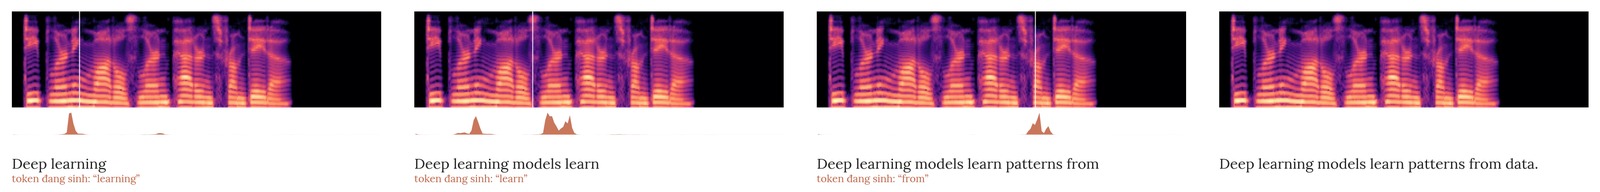

In [ ]:
import numpy as np

query = np.array([[1.0, 0.0]])
keys = np.array([[1.0, 0.0], [0.0, 1.0]])
values = np.array([[2.0, 0.0], [0.0, 2.0]])
scores = query @ keys.T / np.sqrt(keys.shape[1])
weights = np.exp(scores - scores.max(axis=-1, keepdims=True))
weights /= weights.sum(axis=-1, keepdims=True)
context = weights @ values
print("attention:", weights.round(3))
print("context:", context.round(3))

attention: [[0.67 0.33]]
context: [[1.34 0.66]]


Query gần key thứ nhất hơn nên value thứ nhất nhận trọng số 0.67. Một token đích khác có query khác, nên đọc cùng memory nguồn với một hàng trọng số khác. Trọng số attention cho biết decoder đọc từ đâu, nhưng chưa đủ giải thích vì sao model chọn một token: sau attention còn residual, FFN và projection.

**Hỏi nhanh.** Một query đích có điểm, đã chia cho $\sqrt{d_k}$, với ba key nguồn là $(0,\ \ln 3,\ \ln 3)$. Ba value là $(4, 0)$, $(0, 6)$ và $(9, 9)$, trong đó key thứ ba là PAD. Context khi có mask PAD và khi quên mask lần lượt là bao nhiêu?

- A. $(1,\ 4.5)$ và khoảng $(4.43,\ 6.43)$
- B. $(1,\ 4.5)$ ở cả hai trường hợp
- C. Khoảng $(4.43,\ 6.43)$ và $(1,\ 4.5)$
- D. $(4,\ 6)$ và $(13,\ 15)$

<details><summary>Đáp án</summary>

A. $(1,\ 4.5)$ và khoảng $(4.43,\ 6.43)$

Có mask thì softmax trên hai key là $(1, 3)/4 = (0.25,\ 0.75)$, và context là $0.25(4, 0) + 0.75(0, 6) = (1,\ 4.5)$. Quên mask thì trọng số là $(1, 3, 3)/7$, và context là $(4/7 + 27/7,\ 18/7 + 27/7) \approx (4.43,\ 6.43)$. Value của PAD kéo context đi rất xa. Cộng thẳng các value là bỏ qua softmax, không còn là attention.

</details>



## Dịch, tóm tắt và caption cần cách đọc kết quả khác nhau

Dịch có nhiều câu đích cùng đúng, nên exact match quá khắt khe. BLEU so n-gram của bản dịch với bản tham chiếu: precision n-gram có **clipping** (một n-gram chỉ được tính khớp tối đa bằng số lần nó có trong tham chiếu), lấy trung bình nhân theo $n$, rồi nhân **brevity penalty** $\mathrm{BP}=\min(1,\ e^{1-r/c})$, với $c$ là độ dài bản dịch và $r$ là độ dài tham chiếu. BLEU chuẩn dùng tới 4-gram và cộng số đếm trên cả corpus; code dưới tính tới bigram trên một câu để đọc được từng thành phần.

In [ ]:
from collections import Counter
import math

def ngram_counts(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))

def bleu2(candidate, reference):
    precisions = []
    for n in (1, 2):
        counts, ref_counts = ngram_counts(candidate, n), ngram_counts(reference, n)
        clipped = sum(min(count, ref_counts[gram]) for gram, count in counts.items())
        precisions.append(clipped / sum(counts.values()))
    brevity = min(1.0, math.exp(1 - len(reference) / len(candidate)))
    return precisions, brevity, brevity * math.sqrt(precisions[0] * precisions[1])

reference = "câu lạc bộ họp vào thứ sáu".split()
for candidate in ["họp họp họp họp", "câu lạc bộ họp thứ sáu", "câu lạc bộ họp vào thứ bảy"]:
    (p1, p2), bp, score = bleu2(candidate.split(), reference)
    print(f"{candidate:27} p1={p1:.3f} p2={p2:.3f} BP={bp:.3f} BLEU-2={score:.3f}")

họp họp họp họp             p1=0.250 p2=0.000 BP=0.472 BLEU-2=0.000
câu lạc bộ họp thứ sáu      p1=1.000 p2=0.800 BP=0.846 BLEU-2=0.757
câu lạc bộ họp vào thứ bảy  p1=0.857 p2=0.833 BP=1.000 BLEU-2=0.845


Câu lặp `họp` bốn lần chỉ được tính khớp một lần ($p_1=0.25$) và không có bigram nào khớp, nên điểm bằng 0: clipping chặn mẹo lặp từ. Câu thứ hai đúng nội dung nhưng thiếu “vào”, ngắn hơn tham chiếu nên BP bằng 0.846, điểm 0.757. Câu thứ ba đổi thứ sáu thành thứ bảy, sai đúng thông tin quan trọng nhất, vẫn được 0.845, cao hơn câu đúng. Overlap n-gram không kiểm sự thật. BLEU còn phụ thuộc tokenizer (ở đây tách theo âm tiết) và cách tổng hợp trên corpus; khi thi, dùng đúng metric, phiên bản và protocol đề cho, không thay bằng một metric thuận lợi hơn rồi so với điểm chính thức.



Tóm tắt thường chấm bằng ROUGE. ROUGE-N trong định nghĩa gốc là recall n-gram: bao nhiêu n-gram của tham chiếu xuất hiện trong bản tóm tắt; ROUGE-L dựa trên subsequence chung dài nhất. Recall không phạt bản tóm tắt dài dòng, nên đề thường giới hạn độ dài hoặc báo F1.

**Hỏi nhanh.** Đề tóm tắt chấm ROUGE-1 recall, không giới hạn độ dài. Một đội nộp nguyên văn bản nguồn làm “tóm tắt”, và đứng đầu bảng xếp hạng tạm. Điều này cho thấy gì?

- A. Bản nguồn là tóm tắt tốt nhất, vì nó chứa đủ mọi thông tin
- B. ROUGE đã hỏng, vì nó không chạy đúng với văn bản dài
- C. Recall không phạt độ dài, nên metric cần giới hạn độ dài hoặc dùng F1
- D. Đội đó đã đọc trộm bản tham chiếu của tập test

<details><summary>Đáp án</summary>

C. Recall không phạt độ dài, nên metric cần giới hạn độ dài hoặc dùng F1

Phần lớn từ của bản tham chiếu lấy từ nguồn, nên chép cả nguồn gần như phủ hết chúng, và recall gần 1. Precision thì rất thấp, vì phần lớn từ được nộp không có trong tham chiếu. Không cần đọc trộm tham chiếu mới đạt được điểm này. Bài nộp chỉ khai thác đúng chỗ metric không đo.

</details>

Tóm tắt còn cần kiểm người, ngày, số lượng và quan hệ trong nguồn. Câu ngắn nghe hợp lý nhưng đổi “chưa tổ chức” thành “đã tổ chức” là lỗi lớn dù trùng nhiều token. Caption phải đúng đối tượng và hành động trong ảnh; model có thể sinh chi tiết phổ biến nhưng không có trong ảnh. Một tập nhỏ có thể chấm bằng bảng lỗi: thiếu thông tin, thừa chi tiết, đảo quan hệ, sai phủ định và lặp câu. Khi một tài liệu có nhiều bản tham chiếu hoặc bị cắt thành nhiều đoạn, chia train và validation theo tài liệu để nguồn không rò sang validation.

[Recipe text-to-text](recipes/seq2seq_pretrained.py) chạy một encoder–decoder pretrained, FLAN-T5 small, từ snapshot local cho một yêu cầu text-to-text như tóm tắt. Theo [hướng dẫn asset](recipes/README.md), script kiểm repo ID, revision và SHA-256 từng tệp trong manifest trước khi nạp, và không tải gì từ Internet. Prompt được tokenize với giới hạn 256 token; dài hơn thì script dừng, vì nó không tự chia đoạn. `model.generate` giải mã greedy (`do_sample=False`) với `--max-new-tokens` (mặc định 48), rồi in JSON gồm output, thời gian sinh, số token output và, trên CUDA, peak bộ nhớ. Muốn thử beam search, `length_penalty` hay `no_repeat_ngram_size`, thêm chúng vào lời gọi `generate` và so trên cùng tập validation. Caption cần thêm image encoder và bộ xử lý ảnh; đường dẫn ảnh không đi qua tokenizer chữ.

## Bẫy cài đặt

Thư viện seq2seq thường nhận `labels` rồi tự dựng decoder input bằng phép dịch phải, đúng phép ta làm tay với BOS ở trên. Code dưới dựng một T5 rất nhỏ từ config (trọng số ngẫu nhiên, không tải gì) để xem phép dịch ấy trên tensor thật. Quy ước của T5: PAD (ID 0) đồng thời là token mở đầu decoder, EOS có ID 1; vị trí label bằng `-100` bị loss bỏ qua.

In [ ]:
from transformers import T5Config, T5ForConditionalGeneration

config = T5Config(vocab_size=8, d_model=16, d_kv=8, d_ff=32, num_layers=1, num_heads=2,
                  pad_token_id=0, eos_token_id=1, decoder_start_token_id=0)
t5 = T5ForConditionalGeneration(config)
labels = torch.tensor([[4, 3, 1, -100], [5, 1, -100, -100]])
print("decoder input:", t5.prepare_decoder_input_ids_from_labels(labels=labels).tolist())
print("vị trí tính loss:", int((labels != -100).sum()))
labels_with_start = torch.tensor([[0, 4, 3, 1], [0, 5, 1, -100]])
print("label đã có token mở đầu:", t5.prepare_decoder_input_ids_from_labels(labels=labels_with_start).tolist())

decoder input: [[0, 4, 3, 1], [0, 5, 1, 0]]
vị trí tính loss: 5
label đã có token mở đầu: [[0, 0, 4, 3], [0, 0, 5, 1]]


Dòng đầu là label dịch phải một vị trí, có token mở đầu 0 ở trước; `-100` được thay bằng PAD trước khi vào embedding, còn loss chỉ tính 5 vị trí thật. Dòng cuối là lỗi hay gặp: label đã có sẵn token mở đầu nên bị dịch hai lần, và vị trí đầu bị dạy dự đoán PAD thay cho token đích đầu tiên. Quy tắc: khi truyền `labels`, chỉ đưa chuỗi đích kết thúc bằng EOS, pad bằng `-100`, để thư viện tự dịch.



Ngoài shift, hai mask ở mục đầu là nguồn lỗi im lặng: thiếu causal mask làm train loss thấp giả, thiếu mask PAD của nguồn làm output đổi theo batch. Kiểm nhanh bằng bất biến: thêm PAD vào nguồn, hoặc đổi một token đích ở tương lai, thì logits ở các vị trí trước không được đổi.

**Hỏi nhanh.** Fine-tune T5 cho bài tóm tắt. Đội A pad label bằng `-100`, đội B pad bằng PAD, tức ID 0. Hai đội cùng dữ liệu, cùng model, cùng số bước. Train loss của B thấp hơn hẳn của A. Điều này nói lên gì?

- A. Loss của B gồm cả những vị trí PAD dễ đoán, nên thấp mà không tốt hơn
- B. B tốt hơn, vì model học thêm được lúc nào cần dừng sau EOS
- C. Decoder input của A bị dịch sai, vì `-100` không phải token hợp lệ
- D. Hai loss so trực tiếp được, vì cùng dữ liệu và cùng model

<details><summary>Đáp án</summary>

A. Loss của B gồm cả những vị trí PAD dễ đoán, nên thấp mà không tốt hơn

Sau EOS, label của B luôn là PAD. Những vị trí này dễ đoán, cho loss gần 0 và kéo trung bình xuống, đồng thời làm loãng gradient từ các token thật. Lúc nào cần dừng đã được dạy bằng EOS trong label, không cần PAD. Khi dịch label, thư viện thay `-100` bằng PAD, nên decoder input của hai đội như nhau. Hai loss có mẫu số khác nhau, nên không so trực tiếp được.

</details>

## Khi đi thi

- **Đọc metric trước khi chọn cách giải mã.** BLEU phạt câu ngắn, ROUGE recall không phạt câu dài, exact match không cho điểm từng phần; beam size, `length_penalty`, `max_new_tokens` được chọn theo đúng metric đó trên validation.
- **In một bộ nguồn, decoder input và label trước khi train.** Kiểm phép dịch một vị trí, EOS ở cuối label, PAD trong label là `-100`; với thư viện, chỉ truyền `labels` để nó tự dịch.
- **Chọn checkpoint bằng output tự sinh.** Teacher-forced loss là tín hiệu train; mỗi checkpoint cần sinh trên validation và chấm bằng metric của đề.
- **Dự toán thời gian giải mã.** Sinh đi tuần tự từng token, beam rộng $k$ tốn khoảng $k$ lần phép tính của greedy; đo trên đúng thiết bị và batch, đặt `max_new_tokens` để chuỗi không dừng vẫn có giới hạn.
- **Đọc vài chục output bằng mắt.** Tìm cụm lặp, mất phủ định, sai số và ngày, câu bị cắt; metric tự động không bắt hết các lỗi này.
- **Có baseline hợp lệ sớm.** Nguồn dài thì quyết định truncation hay chia đoạn trước; một pipeline nộp đúng định dạng cho biết nên cải thiện ở đâu.

## Tóm tắt

- Encoder–decoder học $p(y\mid x)$: nguồn đọc trọn, đích sinh từ trái sang phải.
- Teacher forcing đưa token đích đúng ở bước trước; label dịch một vị trí, và thư viện tự dịch khi nhận `labels`.
- Cross-attention đặt query đích lên memory nguồn và cần mask PAD của nguồn; khác causal self-attention của decoder.
- Loss teacher-forced cần đi cùng generation; tách loss theo vị trí để biết lỗi do tổng quát hóa hay do tiền tố lệch.
- Beam search tìm chuỗi tốt theo model, không sửa được model sai; tổng log-prob thiên về câu ngắn.
- BLEU và ROUGE đo overlap n-gram, không kiểm sự thật.

## Kiểm tra cuối bài

**Câu 1.** Một model tóm tắt encoder–decoder đọc nguồn 4000 token và sinh tóm tắt 100 token, mọi attention đều đầy đủ. Nếu nguồn tăng lên 8000 token mà tóm tắt vẫn 100 token, thì ma trận điểm của encoder self-attention và của cross-attention lớn lên bao nhiêu lần?

- A. Cả hai lớn lên 2 lần
- B. Cả hai lớn lên 4 lần
- C. Encoder self-attention 4 lần, cross-attention 2 lần
- D. Encoder self-attention 2 lần, cross-attention 4 lần

<details><summary>Đáp án</summary>

C. Encoder self-attention 4 lần, cross-attention 2 lần

Encoder self-attention có ma trận $L_x\times L_x$, từ $4000^2$ lên $8000^2$, tức gấp 4. Đó đúng là chi phí bậc hai $O(n^2)$ theo độ dài chuỗi. Cross-attention có ma trận $L_y\times L_x$, từ $100\cdot 4000$ lên $100\cdot 8000$, tức gấp 2. Decoder self-attention $L_y\times L_y$ không đổi. Với tài liệu dài, phần đắt nhất là encoder, nên bài tóm tắt văn bản dài phải cắt, chia đoạn, hoặc dùng encoder có attention thưa.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 230](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=83)

</details>

**Câu 2.** Bài sửa chính tả: một đội dùng decoder-only thay cho encoder–decoder. Mỗi mẫu là chuỗi `nguồn [SEP] đích`, train theo next-token và tính loss ở mọi vị trí. Muốn objective giống encoder–decoder, tức chỉ học $p(y\mid x)$, thì cần đổi gì?

- A. Bỏ `[SEP]`, vì decoder-only không cần ranh giới giữa hai phần
- B. Thêm cross-attention để phần đích đọc được phần nguồn
- C. Đặt đích trước nguồn để model đọc đáp án trước khi sửa
- D. Đặt label của phần nguồn là `-100`, chỉ tính loss ở phần đích

<details><summary>Đáp án</summary>

D. Đặt label của phần nguồn là `-100`, chỉ tính loss ở phần đích

Tính loss ở mọi vị trí là học cả $p(x)$. Model tốn sức dự đoán câu sai chính tả vốn đã được cho sẵn, và loss trộn hai việc với nhau. Đặt label phần nguồn là `-100` thì chỉ còn các số hạng $\log p(y_t\mid y_{<t}, x)$, đúng objective của encoder–decoder. Causal self-attention trên chuỗi ghép đã cho phần đích đọc toàn bộ phần nguồn đứng trước, nên không cần cross-attention. `[SEP]` đánh dấu chỗ bắt đầu sinh. Đặt đích trước nguồn thì lúc sinh, phần đích chưa thấy nguồn.

</details>

**Câu 3.** Một model sinh caption gồm image encoder biến ảnh thành 196 vector patch, và một text decoder sinh caption. Một bạn đề xuất bỏ cross-attention cho nhẹ, decoder chỉ giữ causal self-attention trên các token chữ. Hậu quả chính là gì?

- A. Không đổi nhiều, vì self-attention trên chữ vẫn thấy được các patch ảnh
- B. Vẫn bám ảnh, vì thông tin ảnh đã nằm sẵn trong embedding chữ
- C. Decoder mất đường đọc ảnh, chỉ còn là một language model trên chữ
- D. Model không train được, vì causal mask phải đi kèm cross-attention

<details><summary>Đáp án</summary>

C. Decoder mất đường đọc ảnh, chỉ còn là một language model trên chữ

Cross-attention là chỗ chữ đặt query lên patch ảnh, với patch ảnh làm key và value. Bỏ nó đi thì self-attention chỉ trộn các token chữ với nhau, nên caption chỉ còn dựa vào thống kê ngôn ngữ, kiểu “một người đang đứng”, bất kể ảnh là gì. Có một thiết kế khác ghép patch vào đầu chuỗi chữ để self-attention đọc được, nhưng đề xuất ở đây không làm vậy. Embedding chữ không chứa gì về ảnh. Causal mask hoạt động độc lập với cross-attention.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 265](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=95)

</details>

**Câu 4.** Train model tóm tắt 12 epoch. Validation loss tính bằng teacher forcing giảm đều tới epoch 12. Còn ROUGE-L của output sinh bằng beam search trên cùng validation thì cao nhất ở epoch 8 rồi giảm. Đề chấm ROUGE-L. Nên nộp checkpoint nào?

- A. Epoch 12, vì validation loss là thước đo ổn định nhất
- B. Epoch 8, vì đề chấm trên chuỗi do model tự sinh ra
- C. Epoch 12, nhưng chuyển sang greedy để ROUGE-L tăng lại
- D. Trung bình trọng số epoch 8 và 12 để lấy cả hai ưu điểm

<details><summary>Đáp án</summary>

B. Epoch 8, vì đề chấm trên chuỗi do model tự sinh ra

Validation loss đo xác suất của tham chiếu khi được cho tiền tố đúng. Đề thì chấm chuỗi tự sinh, nên phải chọn theo ROUGE-L của output. Hai đại lượng này có thể lệch nhau, chẳng hạn khi model ngày càng tự tin vào câu ngắn hoặc cụm từ lặp. Đổi sang greedy là đổi bộ giải mã, phải đo chứ không mặc định là ROUGE-L sẽ tăng. Trung bình trọng số là một thí nghiệm khác, cũng phải đo trước khi nộp.

</details>

**Câu 5.** Bản tham chiếu dài 10 token. Brevity penalty của BLEU bằng bao nhiêu khi bản dịch dài 8 token, và khi bản dịch dài 12 token?

- A. $0.8$ và $1.2$
- B. $1$ và khoảng $0.779$
- C. Khoảng $0.779$ và khoảng $1.18$
- D. Khoảng $0.779$ và $1$

<details><summary>Đáp án</summary>

D. Khoảng $0.779$ và $1$

Với $c = 8$, $\mathrm{BP} = e^{1 - 10/8} = e^{-0.25} \approx 0.779$. Với $c = 12$, $e^{1 - 10/12} \approx 1.18$, nhưng BP lấy $\min$ với 1, nên bằng 1. BLEU không thưởng bản dịch dài, vì từ thừa đã làm precision giảm rồi. Tỉ số độ dài $8/10$ không phải BP. Đảo hai giá trị là nhầm chiều phạt.

</details>

**Câu 6.** Một model dịch có loss teacher forcing thấp nhưng exact match khi tự sinh lại thấp. Thí nghiệm nào kiểm được giả thuyết “lỗi bắt nguồn từ việc tiền tố tự sinh lệch khỏi tiền tố đúng”?

- A. Chấm lại loss trên validation, vẫn với tiền tố đúng như cũ
- B. Tăng beam size rồi xem exact match có tăng không
- C. So dự đoán từng vị trí khi được cho tiền tố đúng và khi tự sinh
- D. Đổi exact match sang BLEU rồi xem điểm có tăng không

<details><summary>Đáp án</summary>

C. So dự đoán từng vị trí khi được cho tiền tố đúng và khi tự sinh

Nếu với tiền tố đúng model đoán đúng vị trí $t$, nhưng khi tự sinh lại sai từ sau token sai đầu tiên, thì lỗi lan từ tiền tố. Đó đúng là exposure bias. Nếu với tiền tố đúng mà vẫn sai, như C C trong bài, thì lỗi nằm ở model. Chấm lại loss với tiền tố đúng không nhìn thấy tiền tố tự sinh. Tăng beam hay đổi metric là đổi cách sinh hoặc cách chấm, không tách được hai nguyên nhân.

</details>

**Câu 7.** Dataset tóm tắt có 2000 bài báo, mỗi bài có 3 bản tóm tắt tham chiếu do ba người viết. Một đội tách thành 6000 cặp (bài, tóm tắt) rồi chia ngẫu nhiên 80/20. ROUGE trên validation cao bất thường so với leaderboard. Nguyên nhân khả dĩ nhất là gì?

- A. 6000 cặp là quá ít nên ROUGE validation dao động mạnh
- B. Một bài báo có cặp nằm ở cả train lẫn validation
- C. Ba người viết khác nhau làm tham chiếu nhiễu, đẩy ROUGE lên
- D. Tỉ lệ 80/20 không hợp, dữ liệu tóm tắt cần chia 50/50

<details><summary>Đáp án</summary>

B. Một bài báo có cặp nằm ở cả train lẫn validation

Mỗi cặp validation có hai cặp “anh em” cùng bài báo, mỗi cặp vào train với xác suất 0.8. Vì vậy khoảng $1 - 0.2^2 = 96\%$ số cặp validation có bài báo mà model đã gặp, kèm một bản tóm tắt gần giống. Phải chia theo bài báo, tức group split, để ba tham chiếu của một bài nằm cùng một phía. Tham chiếu nhiễu thường làm ROUGE thấp đi chứ không cao lên. Tỉ lệ chia không gây chênh lệch có hệ thống.

</details>

**Câu 8.** Một model dịch dựng như GRU trong bài: encoder dồn cả câu nguồn vào một vector 24 số rồi giao cho decoder. Với câu nguồn trên 40 token, bản dịch hay bỏ sót ý ở đầu câu. Thêm cross-attention vào decoder giúp đúng ở chỗ nào?

- A. Mỗi bước sinh đọc lại mọi vị trí nguồn, theo trọng số riêng
- B. Nén cả câu nguồn thành một vector cố định giàu thông tin hơn
- C. Cho decoder nhìn trước các token đích chưa sinh của bản dịch
- D. Cho decoder sinh mọi token đích song song, không chờ tiền tố

<details><summary>Đáp án</summary>

A. Mỗi bước sinh đọc lại mọi vị trí nguồn, theo trọng số riêng

GRU dồn mọi thông tin của nguồn vào một trạng thái có kích thước cố định trước khi decoder bắt đầu. Ý ở đầu một câu dài vì vậy phải sống sót qua hàng chục bước cập nhật. Cross-attention giữ hidden state của mọi vị trí nguồn làm key và value. Ở mỗi bước sinh, query của decoder tính trọng số lên chúng rồi lấy tổ hợp, nên ý ở đầu câu vẫn được đọc trực tiếp. Attention không nén nguồn thành một vector cố định, vì đó chính là nút thắt nó gỡ bỏ. Nhìn trước token đích là lộ đáp án, và causal mask vẫn cấm. Lúc sinh, token sau phụ thuộc token vừa chọn, nên không thể sinh song song.
Phỏng theo: [NOAI 2025 Singapore · Phần 1 · Câu 16](https://learn.aisingapore.org/wp-content/uploads/2025/10/NOAI-2025-MCQ-Assessment-Questions.pdf#page=3)

</details>

**Câu 9.** Fine-tune T5 cho bài dịch. Label được tạo bằng tokenizer với `add_special_tokens=False`, nên không có EOS ở cuối. Train loss giảm bình thường. Khi sinh với `max_new_tokens=64`, hiện tượng nào dễ xảy ra nhất?

- A. Output dừng ngay sau vài token vì thiếu tín hiệu kết thúc
- B. Output như cũ, vì EOS chỉ là token định dạng khi in ra
- C. Code báo lỗi shape khi tính loss, vì label ngắn hơn một token
- D. Output thường chạy tới 64 token, phần cuối lặp lại hoặc lạc đề

<details><summary>Đáp án</summary>

D. Output thường chạy tới 64 token, phần cuối lặp lại hoặc lạc đề

Model không còn được dạy dự đoán EOS sau nội dung, nên xác suất EOS ở mọi bước bị đẩy xuống, và vòng sinh chỉ dừng khi chạm `max_new_tokens`. Thư viện tự dịch label để tạo decoder input, nên label ngắn hơn không gây lỗi shape. Muốn model biết lúc dừng, chuỗi đích phải kết thúc bằng EOS, như label `B A EOS` trong bài.

</details>

**Câu 10.** Decoder transformer, chuỗi đích dài 50 token kể cả EOS. Khi train với teacher forcing, và khi sinh greedy, mỗi mẫu cần bao nhiêu lượt chạy decoder?

- A. Train cần 1 lượt cho cả 50 vị trí, còn sinh cần 50 lượt nối tiếp
- B. Train cần 50 lượt nối tiếp, còn sinh cần 1 lượt cho cả 50 vị trí
- C. Cả hai cần 1 lượt, nhờ causal mask cho chạy song song
- D. Cả hai cần 50 lượt nối tiếp, mỗi lượt một token

<details><summary>Đáp án</summary>

A. Train cần 1 lượt cho cả 50 vị trí, còn sinh cần 50 lượt nối tiếp

Teacher forcing có sẵn toàn bộ decoder input, và causal mask cho phép tính 50 vị trí trong một lượt. Lúc sinh, token $t + 1$ phụ thuộc token $t$ vừa chọn, nên phải chạy 50 lượt nối tiếp. Lưu lại phần đã tính cho tiền tố, như KV cache ở bài 6.6, chỉ làm mỗi lượt rẻ hơn, không gộp được các lượt. Vì vậy thời gian sinh, chứ không phải thời gian train một bước, thường là phần cần dự toán kỹ trong ngân sách thi.

</details>

## Đọc thêm

- Dive into Deep Learning — [Sequence-to-sequence learning](https://d2l.ai/chapter_recurrent-modern/seq2seq.html) và [Transformer](https://d2l.ai/chapter_attention-mechanisms-and-transformers/transformer.html). Đọc teacher forcing rồi nối sang cross-attention.
- Vaswani và cộng sự — [Attention Is All You Need](https://arxiv.org/abs/1706.03762). Nguồn kiến trúc transformer encoder–decoder.
- Jurafsky, Martin — [Machine Translation](https://web.stanford.edu/~jurafsky/slp3/13.pdf). Đọc cách đánh giá bản dịch và giới hạn của overlap.
- Papineni và cộng sự — [BLEU](https://aclanthology.org/P02-1040/); Lin — [ROUGE](https://aclanthology.org/W04-1013/). Xem định nghĩa metric thay vì chỉ gọi tên.
- Post — [A Call for Clarity in Reporting BLEU Scores](https://aclanthology.org/W18-6319/). Vì sao cùng một bản dịch cho BLEU khác nhau theo tokenizer, và cách báo điểm tái lập được.
- Hugging Face — [Generation strategies](https://huggingface.co/docs/transformers/generation_strategies). Đọc `num_beams`, `length_penalty`, `no_repeat_ngram_size` trước khi gọi `generate`.
- Model card — [FLAN-T5 small](https://huggingface.co/google/flan-t5-small). Kiểm mục đích, tokenizer và license trước khi chuẩn bị asset text-to-text.

Nguồn âm thanh: các câu tiếng Anh trong hình động được đọc bằng giọng tổng hợp có sẵn của Windows (Microsoft Zira, Microsoft David).